In [3]:
# Core Libraries
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score,
                                         GridSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix,
                                roc_curve, auc, precision_recall_curve,
                                average_precision_score, accuracy_score)
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

# Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats

# Global dark theme
plt.rcParams.update({
    'figure.facecolor': '#0d1117', 'axes.facecolor': '#161b22',
    'axes.edgecolor': '#30363d',  'axes.labelcolor': '#c9d1d9',
    'xtick.color': '#8b949e',    'ytick.color': '#8b949e',
    'text.color': '#c9d1d9',     'grid.color': '#21262d',
    'grid.linewidth': 0.8,
})
COLORS = {
    'primary': '#58a6ff', 'secondary': '#f78166',
    'success': '#3fb950',  'warning': '#d29922',
    'purple': '#bc8cff',   'bg': '#0d1117',
    'card': '#161b22',     'border': '#30363d',
}
kernel_colors = [COLORS['primary'], COLORS['success'],
                 COLORS['warning'], COLORS['purple']]
print('✅ Libraries loaded!')

✅ Libraries loaded!


In [4]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df['diagnosis'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

print('=' * 55)
print(f'  Samples : {df.shape[0]}')
print(f'  Features: {df.shape[1]-2}')
print(f'  Malignant: {(df.target==0).sum()} | Benign: {(df.target==1).sum()}')
print('=' * 55)
df.head()

  Samples : 569
  Features: 30
  Malignant: 212 | Benign: 357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


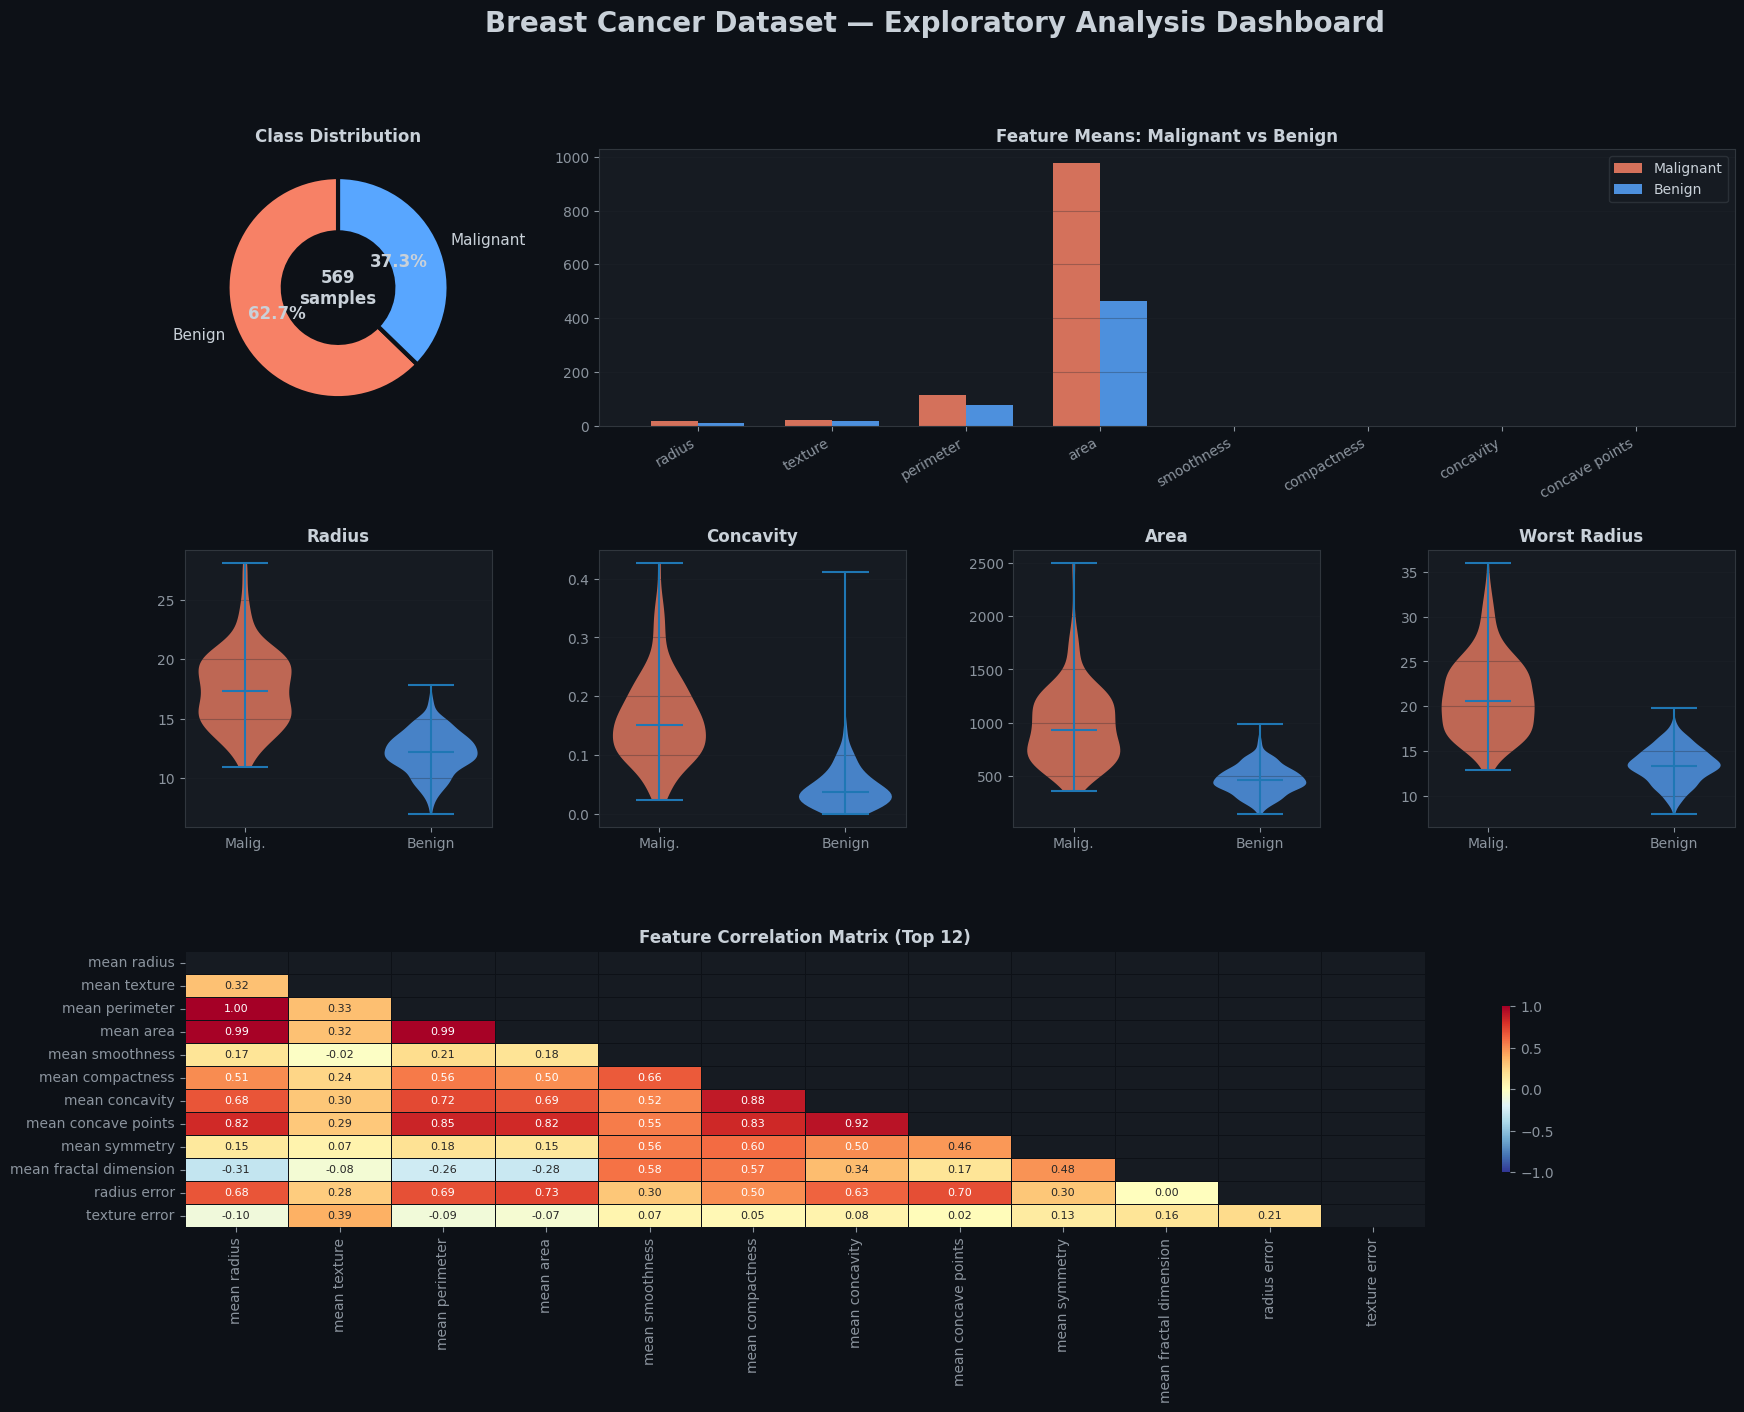

In [3]:
fig = plt.figure(figsize=(20, 14), facecolor=COLORS['bg'])
fig.suptitle('Breast Cancer Dataset — Exploratory Analysis Dashboard',
             fontsize=20, fontweight='bold', color='#c9d1d9', y=0.98)
gs = gridspec.GridSpec(3, 4, figure=fig, hspace=0.45, wspace=0.35)

# ── Donut chart
ax1 = fig.add_subplot(gs[0, 0])
counts = df['diagnosis'].value_counts()
wedge_props = dict(width=0.5, edgecolor=COLORS['bg'], linewidth=3)
wedges, texts, autotexts = ax1.pie(
    counts, labels=counts.index, autopct='%1.1f%%',
    colors=[COLORS['secondary'], COLORS['primary']],
    wedgeprops=wedge_props, startangle=90,
    textprops={'color': '#c9d1d9', 'fontsize': 11}
)
for at in autotexts: at.set_fontsize(12); at.set_fontweight('bold')
ax1.set_title('Class Distribution', color='#c9d1d9', fontweight='bold')
ax1.text(0, 0, f'{df.shape[0]}\nsamples', ha='center', va='center',
         fontsize=12, fontweight='bold', color='#c9d1d9')

# ── Feature means bar chart
ax2 = fig.add_subplot(gs[0, 1:])
top_features = ['mean radius', 'mean texture', 'mean perimeter',
                'mean area', 'mean smoothness', 'mean compactness',
                'mean concavity', 'mean concave points']
malignant_means = df[df.target==0][top_features].mean()
benign_means    = df[df.target==1][top_features].mean()
x = np.arange(len(top_features))
ax2.bar(x - 0.35, malignant_means, 0.35, label='Malignant', color=COLORS['secondary'], alpha=0.85)
ax2.bar(x,        benign_means,    0.35, label='Benign',    color=COLORS['primary'],   alpha=0.85)
ax2.set_xticks(x - 0.175)
ax2.set_xticklabels([f.replace('mean ', '') for f in top_features], rotation=30, ha='right')
ax2.legend(facecolor=COLORS['card'], edgecolor=COLORS['border'], labelcolor='#c9d1d9')
ax2.set_title('Feature Means: Malignant vs Benign', color='#c9d1d9', fontweight='bold')
ax2.set_facecolor(COLORS['card']); ax2.grid(axis='y', alpha=0.3)

# ── Violin plots
key_feats = ['mean radius', 'mean concavity', 'mean area', 'worst radius']
for i, feat in enumerate(key_feats):
    ax = fig.add_subplot(gs[1, i])
    parts = ax.violinplot([df[df.target==0][feat], df[df.target==1][feat]],
                           positions=[0,1], showmedians=True)
    for pc, col in zip(parts['bodies'], [COLORS['secondary'], COLORS['primary']]):
        pc.set_facecolor(col); pc.set_alpha(0.75)
    ax.set_xticks([0,1]); ax.set_xticklabels(['Malig.', 'Benign'])
    ax.set_title(feat.replace('mean ','').title(), color='#c9d1d9', fontweight='bold')
    ax.set_facecolor(COLORS['card']); ax.grid(axis='y', alpha=0.3)

# ── Correlation heatmap
ax5 = fig.add_subplot(gs[2, :])
corr = df[data.feature_names[:12]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, ax=ax5, cmap='RdYlBu_r', vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size':8},
            linewidths=0.5, linecolor=COLORS['bg'], cbar_kws={'shrink':0.6})
ax5.set_title('Feature Correlation Matrix (Top 12)', color='#c9d1d9', fontweight='bold')

plt.savefig('viz1_eda_dashboard.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

In [4]:
# Split & scale
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Train all 4 kernels
kernels = ['linear', 'rbf', 'poly', 'sigmoid']
results = {}
for kernel in kernels:
    model = SVC(kernel=kernel, C=1.0, gamma='scale', probability=True, random_state=42)
    model.fit(X_train_sc, y_train)
    y_pred = model.predict(X_test_sc)
    y_prob = model.predict_proba(X_test_sc)[:, 1]
    cv_sc  = cross_val_score(model, X_train_sc, y_train, cv=5, scoring='accuracy')
    results[kernel] = {
        'model': model, 'y_pred': y_pred, 'y_prob': y_prob,
        'accuracy': accuracy_score(y_test, y_pred),
        'cv_mean': cv_sc.mean(), 'cv_std': cv_sc.std(),
        'cm': confusion_matrix(y_test, y_pred),
        'report': classification_report(y_test, y_pred,
                       target_names=['Malignant','Benign'], output_dict=True),
    }
    print(f'  [{kernel:>8}]  Acc: {results[kernel]["accuracy"]*100:.2f}%  CV: {results[kernel]["cv_mean"]*100:.2f}% ± {results[kernel]["cv_std"]*100:.2f}%')
best_kernel = max(results, key=lambda k: results[k]['accuracy'])
print(f'\n Best kernel: {best_kernel.upper()}')

  [  linear]  Acc: 97.37%  CV: 96.70% ± 1.39%
  [     rbf]  Acc: 98.25%  CV: 97.14% ± 1.79%
  [    poly]  Acc: 91.23%  CV: 89.67% ± 2.15%
  [ sigmoid]  Acc: 92.98%  CV: 96.92% ± 1.28%

🏆 Best kernel: RBF


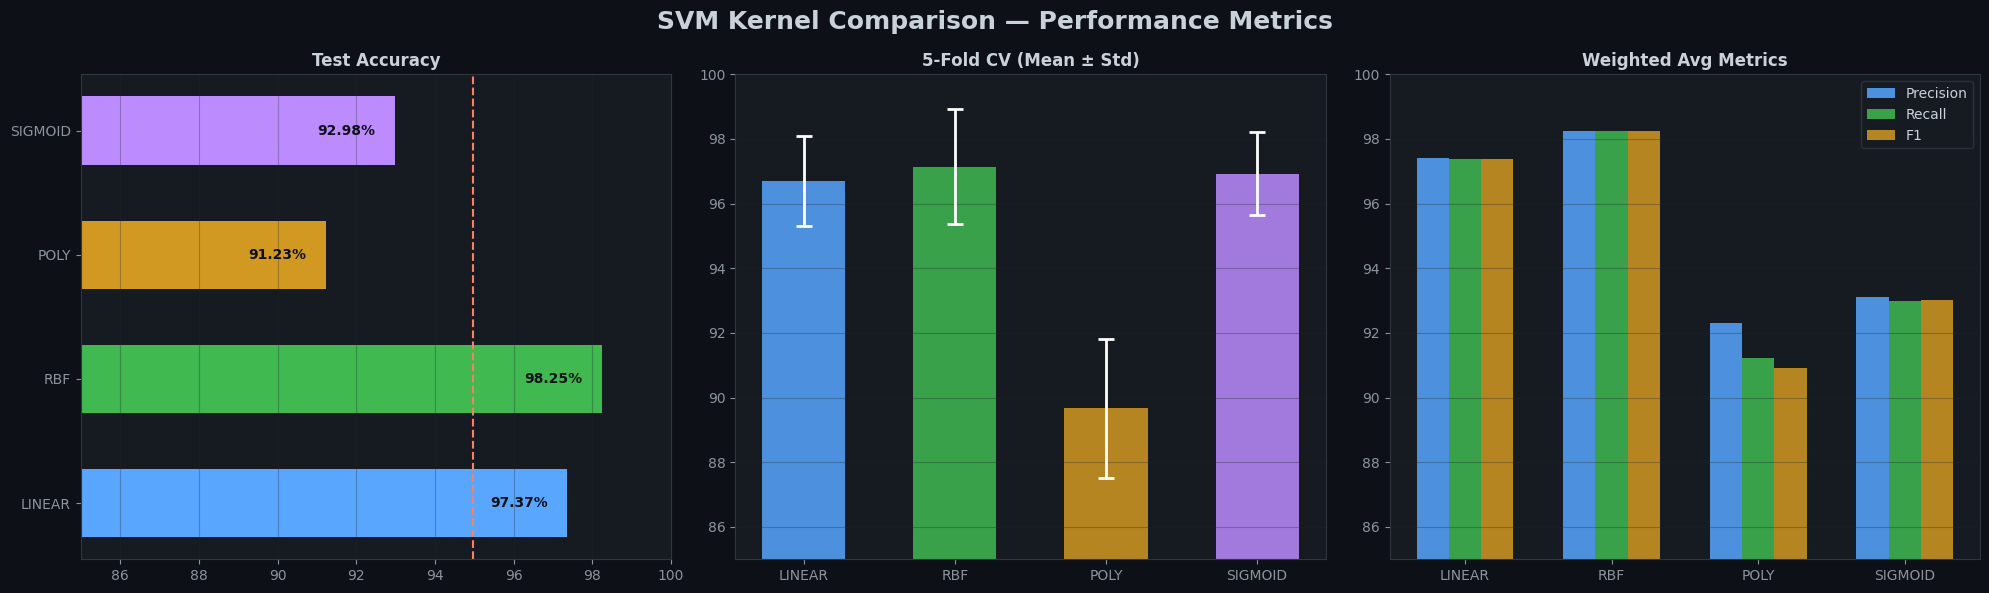

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6), facecolor=COLORS['bg'])
fig.suptitle('SVM Kernel Comparison — Performance Metrics',
             fontsize=18, fontweight='bold', color='#c9d1d9')
kernel_labels = [k.upper() for k in kernels]

# Accuracy bars
ax = axes[0]
accs = [results[k]['accuracy']*100 for k in kernels]
bars = ax.barh(kernel_labels, accs, color=kernel_colors, height=0.55)
for bar, val in zip(bars, accs):
    ax.text(val-0.5, bar.get_y()+bar.get_height()/2, f'{val:.2f}%',
            va='center', ha='right', fontweight='bold', color='#0d1117')
ax.set_xlim(85, 100); ax.set_title('Test Accuracy', color='#c9d1d9', fontweight='bold')
ax.set_facecolor(COLORS['card']); ax.grid(axis='x', alpha=0.3)
ax.axvline(np.mean(accs), color=COLORS['secondary'], linestyle='--', linewidth=1.5)

# CV scores with error bars
ax = axes[1]
cv_means = [results[k]['cv_mean']*100 for k in kernels]
cv_stds  = [results[k]['cv_std']*100  for k in kernels]
x_pos = np.arange(len(kernels))
ax.bar(x_pos, cv_means, color=kernel_colors, width=0.55, alpha=0.85)
ax.errorbar(x_pos, cv_means, yerr=cv_stds, fmt='none',
             color='white', capsize=6, capthick=2, linewidth=2)
ax.set_xticks(x_pos); ax.set_xticklabels(kernel_labels)
ax.set_ylim(85, 100); ax.set_title('5-Fold CV (Mean ± Std)', color='#c9d1d9', fontweight='bold')
ax.set_facecolor(COLORS['card']); ax.grid(axis='y', alpha=0.3)

# Grouped precision / recall / F1
ax = axes[2]
metric_c = [COLORS['primary'], COLORS['success'], COLORS['warning']]
for mi, (m, mc, ml) in enumerate(zip(
    ['precision','recall','f1-score'], metric_c, ['Precision','Recall','F1'])):
    vals = [results[k]['report']['weighted avg'][m]*100 for k in kernels]
    ax.bar(x_pos+(mi-1)*0.22, vals, 0.22, label=ml, color=mc, alpha=0.85)
ax.set_xticks(x_pos); ax.set_xticklabels(kernel_labels)
ax.set_ylim(85, 100); ax.set_title('Weighted Avg Metrics', color='#c9d1d9', fontweight='bold')
ax.legend(facecolor=COLORS['card'], edgecolor=COLORS['border'], labelcolor='#c9d1d9')
ax.set_facecolor(COLORS['card']); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('viz2_kernel_comparison.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

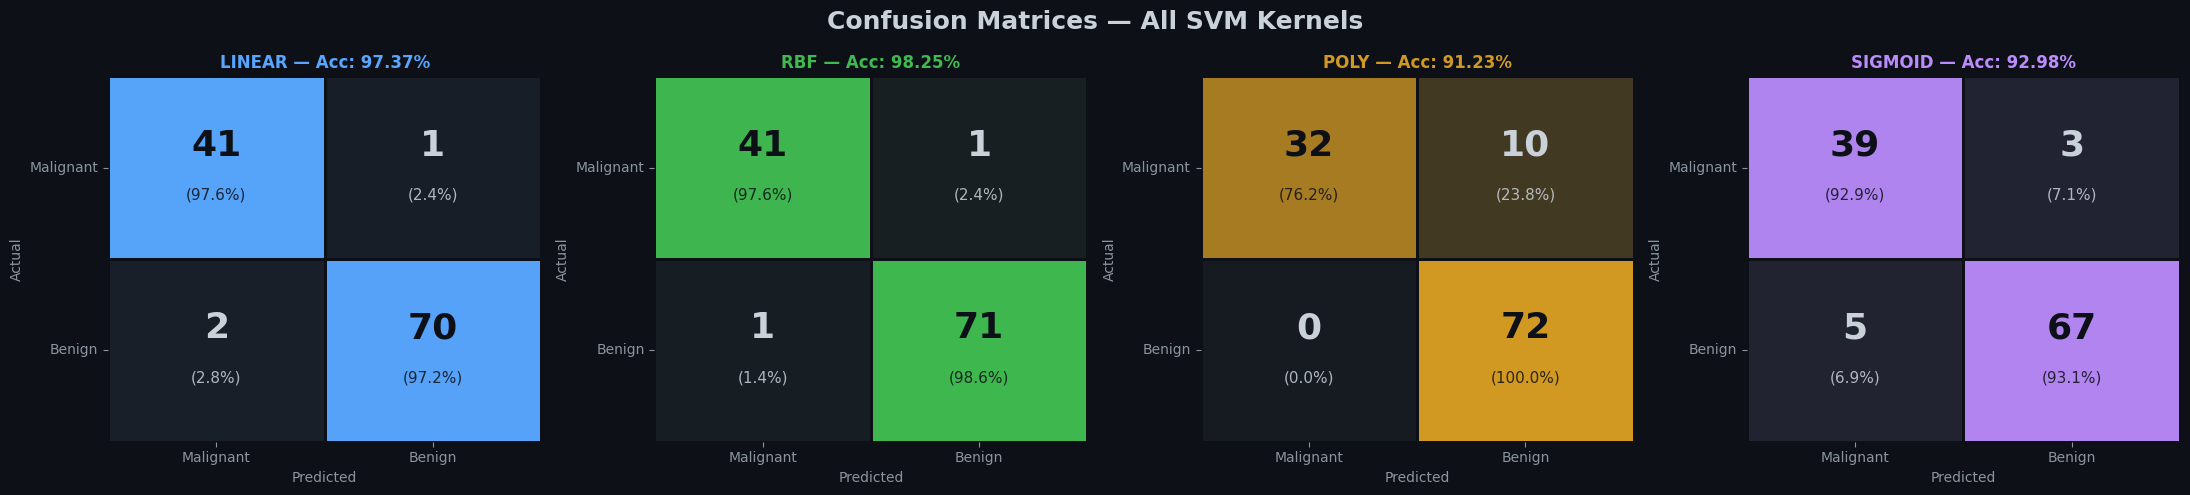

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5), facecolor=COLORS['bg'])
fig.suptitle('Confusion Matrices — All SVM Kernels',
             fontsize=18, fontweight='bold', color='#c9d1d9')

for ax, kernel, kcolor in zip(axes, kernels, kernel_colors):
    cm = results[kernel]['cm']
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    cmap_c = LinearSegmentedColormap.from_list('', [COLORS['card'], kcolor])
    sns.heatmap(cm_pct, annot=False, ax=ax, cmap=cmap_c, vmin=0, vmax=100,
                linewidths=2, linecolor=COLORS['bg'], cbar=False)
    for i in range(2):
        for j in range(2):
            tc = '#0d1117' if cm_pct[i,j] > 50 else '#c9d1d9'
            ax.text(j+0.5, i+0.38, f'{cm[i,j]}',
                    ha='center', va='center', fontsize=26, fontweight='bold', color=tc)
            ax.text(j+0.5, i+0.65, f'({cm_pct[i,j]:.1f}%)',
                    ha='center', va='center', fontsize=11, color=tc, alpha=0.85)
    ax.set_xticklabels(['Malignant','Benign'])
    ax.set_yticklabels(['Malignant','Benign'], rotation=0)
    ax.set_xlabel('Predicted', color='#8b949e')
    ax.set_ylabel('Actual', color='#8b949e')
    ax.set_title(f'{kernel.upper()} — Acc: {results[kernel]["accuracy"]*100:.2f}%',
                 color=kcolor, fontweight='bold')

plt.tight_layout()
plt.savefig('viz3_confusion_matrices.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

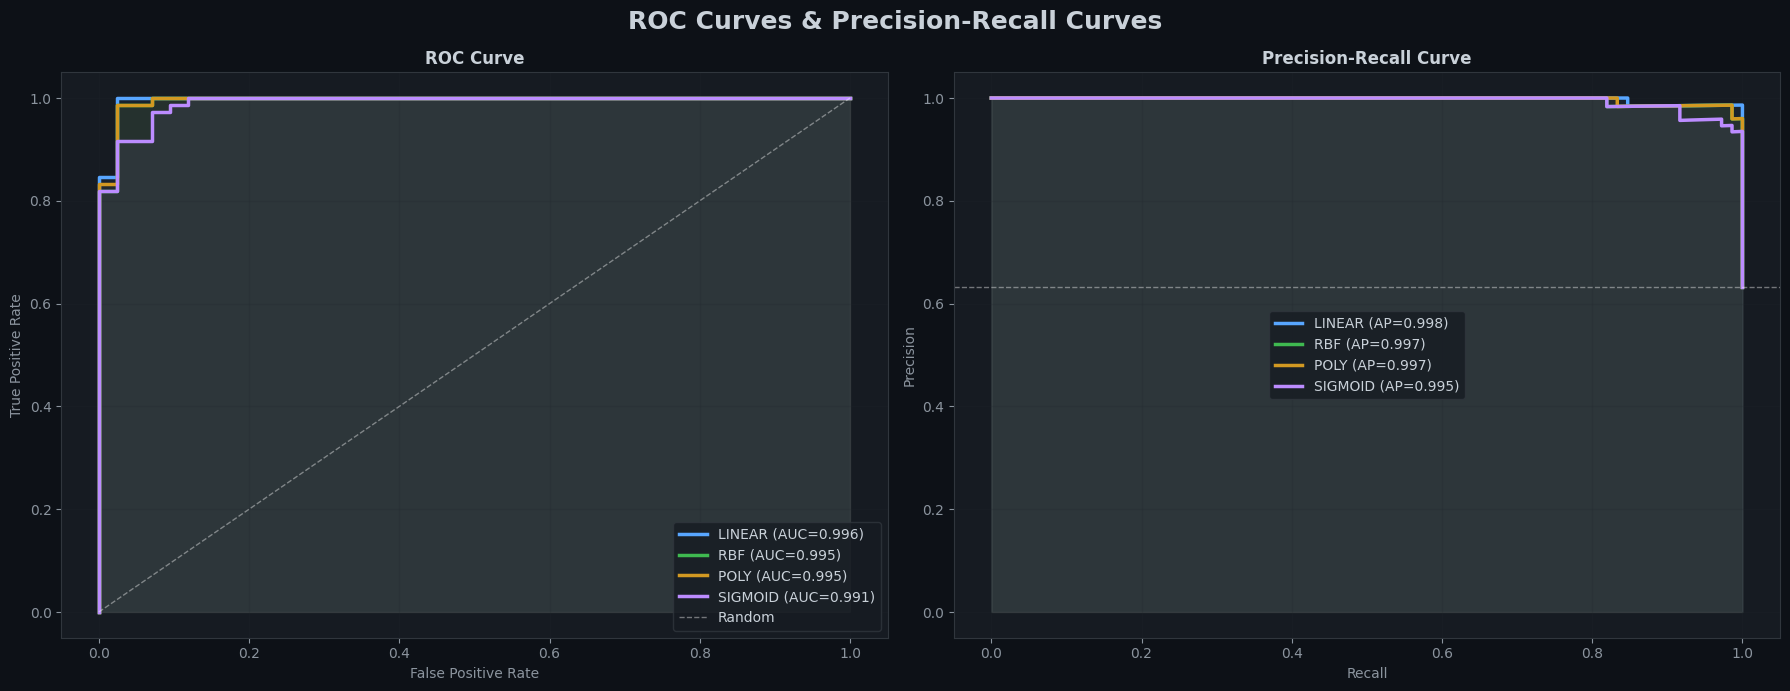

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), facecolor=COLORS['bg'])
fig.suptitle('ROC Curves & Precision-Recall Curves',
             fontsize=18, fontweight='bold', color='#c9d1d9')

# ROC
ax = axes[0]
for kernel, kcolor in zip(kernels, kernel_colors):
    fpr, tpr, _ = roc_curve(y_test, results[kernel]['y_prob'])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=kcolor, linewidth=2.5,
            label=f'{kernel.upper()} (AUC={roc_auc:.3f})')
    ax.fill_between(fpr, tpr, alpha=0.06, color=kcolor)
ax.plot([0,1], [0,1], 'w--', linewidth=1, alpha=0.4, label='Random')
ax.set_xlabel('False Positive Rate', color='#8b949e')
ax.set_ylabel('True Positive Rate', color='#8b949e')
ax.set_title('ROC Curve', color='#c9d1d9', fontweight='bold')
ax.legend(facecolor=COLORS['card'], edgecolor=COLORS['border'], labelcolor='#c9d1d9', loc='lower right')
ax.set_facecolor(COLORS['card']); ax.grid(alpha=0.2)

# PR Curve
ax = axes[1]
for kernel, kcolor in zip(kernels, kernel_colors):
    prec, rec, _ = precision_recall_curve(y_test, results[kernel]['y_prob'])
    ap = average_precision_score(y_test, results[kernel]['y_prob'])
    ax.plot(rec, prec, color=kcolor, linewidth=2.5, label=f'{kernel.upper()} (AP={ap:.3f})')
    ax.fill_between(rec, prec, alpha=0.06, color=kcolor)
ax.axhline(y_test.mean(), color='white', linestyle='--', linewidth=1, alpha=0.4)
ax.set_xlabel('Recall', color='#8b949e'); ax.set_ylabel('Precision', color='#8b949e')
ax.set_title('Precision-Recall Curve', color='#c9d1d9', fontweight='bold')
ax.legend(facecolor=COLORS['card'], edgecolor=COLORS['border'], labelcolor='#c9d1d9')
ax.set_facecolor(COLORS['card']); ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig('viz4_roc_pr_curves.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

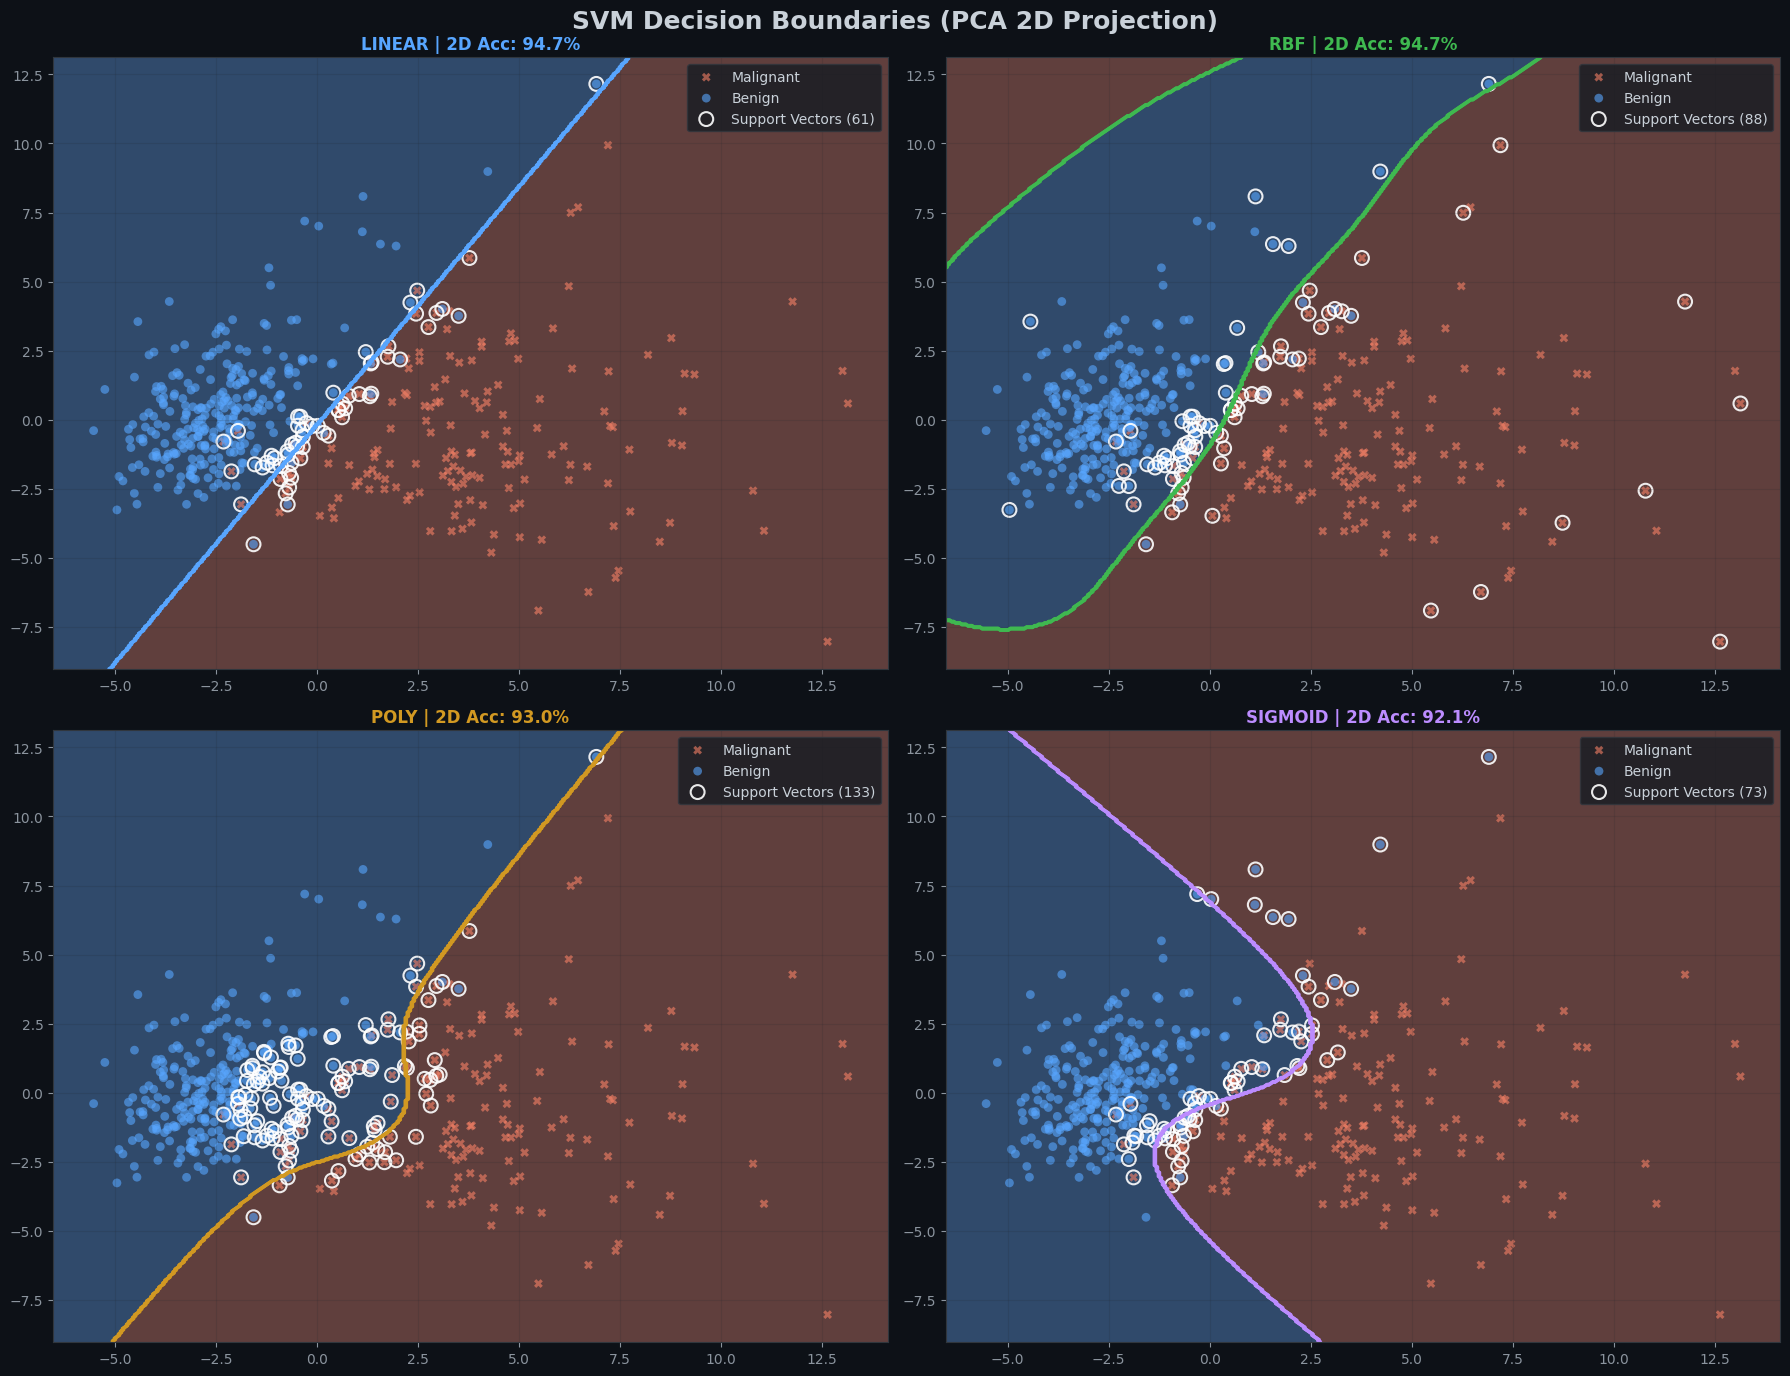

In [8]:
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_sc)
X_test_2d  = pca.transform(X_test_sc)

fig, axes = plt.subplots(2, 2, figsize=(18, 14), facecolor=COLORS['bg'])
fig.suptitle('SVM Decision Boundaries (PCA 2D Projection)',
             fontsize=18, fontweight='bold', color='#c9d1d9')
x_min, x_max = X_train_2d[:,0].min()-1, X_train_2d[:,0].max()+1
y_min, y_max = X_train_2d[:,1].min()-1, X_train_2d[:,1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                      np.arange(y_min, y_max, 0.05))

for ax, kernel, kcolor in zip(axes.flatten(), kernels, kernel_colors):
    svm2d = SVC(kernel=kernel, C=1.0, gamma='scale', probability=True, random_state=42)
    svm2d.fit(X_train_2d, y_train)
    Z = svm2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    bg_cmap = LinearSegmentedColormap.from_list('',
               [COLORS['secondary']+'55', COLORS['primary']+'55'])
    ax.contourf(xx, yy, Z, alpha=0.35, cmap=bg_cmap)
    ax.contour(xx, yy, Z, colors=kcolor, linewidths=2, alpha=0.9)
    for cls, mk, col, lbl in [(0,'X',COLORS['secondary'],'Malignant'),
                               (1,'o',COLORS['primary'],'Benign')]:
        m = y_train==cls
        ax.scatter(X_train_2d[m,0], X_train_2d[m,1], c=col, marker=mk, s=40,
                   alpha=0.6, edgecolors='none', label=lbl)
    sv = svm2d.support_vectors_
    ax.scatter(sv[:,0], sv[:,1], s=100, facecolors='none',
               edgecolors='white', linewidths=1.5, alpha=0.9,
               label=f'Support Vectors ({len(sv)})')
    acc2d = svm2d.score(X_test_2d, y_test)
    ax.set_title(f'{kernel.upper()} | 2D Acc: {acc2d*100:.1f}%', color=kcolor, fontweight='bold')
    ax.set_facecolor(COLORS['card']); ax.grid(alpha=0.15)
    ax.legend(facecolor=COLORS['card'], edgecolor=COLORS['border'], labelcolor='#c9d1d9')

plt.tight_layout()
plt.savefig('viz5_decision_boundaries.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

Best params : {'C': 10, 'gamma': 0.01}
Test accuracy: 98.25%


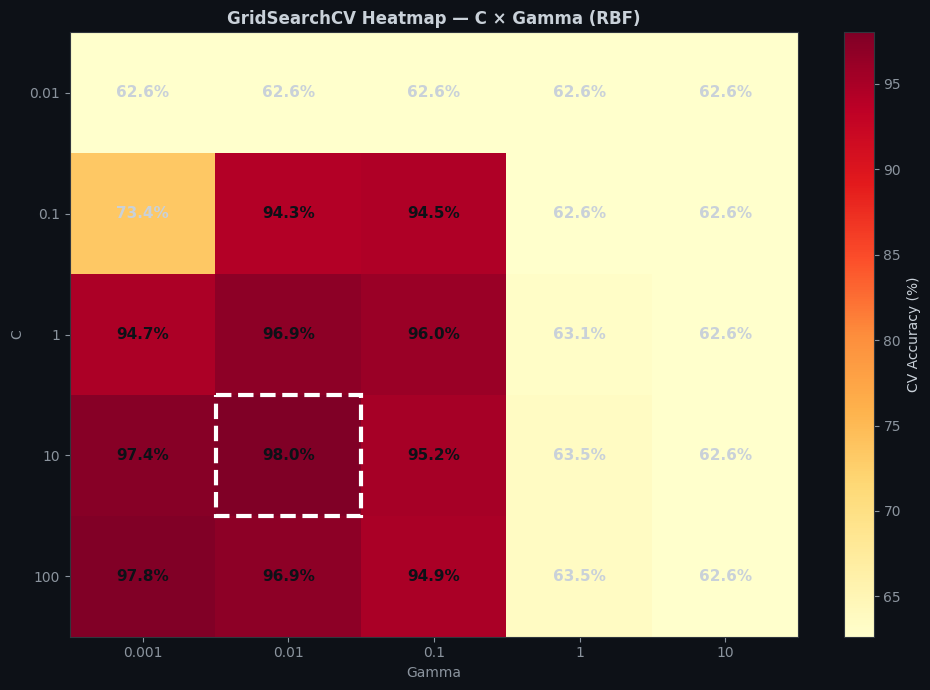

In [13]:
param_grid = {'C': [0.01,0.1,1,10,100], 'gamma': [0.001,0.01,0.1,1,10]}
grid_search = GridSearchCV(
    SVC(kernel='rbf', probability=True, random_state=42),
    param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_sc, y_train)
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_sc)
y_prob_best = best_model.predict_proba(X_test_sc)[:, 1]
print(f'Best params : {grid_search.best_params_}')
print(f'Test accuracy: {accuracy_score(y_test,y_pred_best)*100:.2f}%')

# Heatmap
scores_matrix = grid_search.cv_results_['mean_test_score'].reshape(
    len(param_grid['C']), len(param_grid['gamma']))
fig, ax = plt.subplots(figsize=(10, 7), facecolor=COLORS['bg'])
im = ax.imshow(scores_matrix*100, cmap='YlOrRd', aspect='auto')
plt.colorbar(im, ax=ax).set_label('CV Accuracy (%)', color='#c9d1d9')
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels([str(g) for g in param_grid['gamma']])
ax.set_yticklabels([str(c) for c in param_grid['C']])
ax.set_xlabel('Gamma', color='#8b949e'); ax.set_ylabel('C', color='#8b949e')
ax.set_title('GridSearchCV Heatmap — C × Gamma (RBF)', color='#c9d1d9', fontweight='bold')
ax.set_facecolor(COLORS['card'])
for i in range(5):
    for j in range(5):
        tc = '#0d1117' if scores_matrix[i,j]*100 > 93 else '#c9d1d9'
        ax.text(j, i, f'{scores_matrix[i,j]*100:.1f}%',
                ha='center', va='center', fontsize=11, fontweight='bold', color=tc)
best_i = param_grid['C'].index(grid_search.best_params_['C'])
best_j = param_grid['gamma'].index(grid_search.best_params_['gamma'])
ax.add_patch(plt.Rectangle((best_j-0.5, best_i-0.5), 1, 1,
              fill=False, edgecolor='white', linewidth=3, linestyle='--'))
plt.tight_layout()
plt.savefig('viz6_gridsearch_heatmap.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.savefig('Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

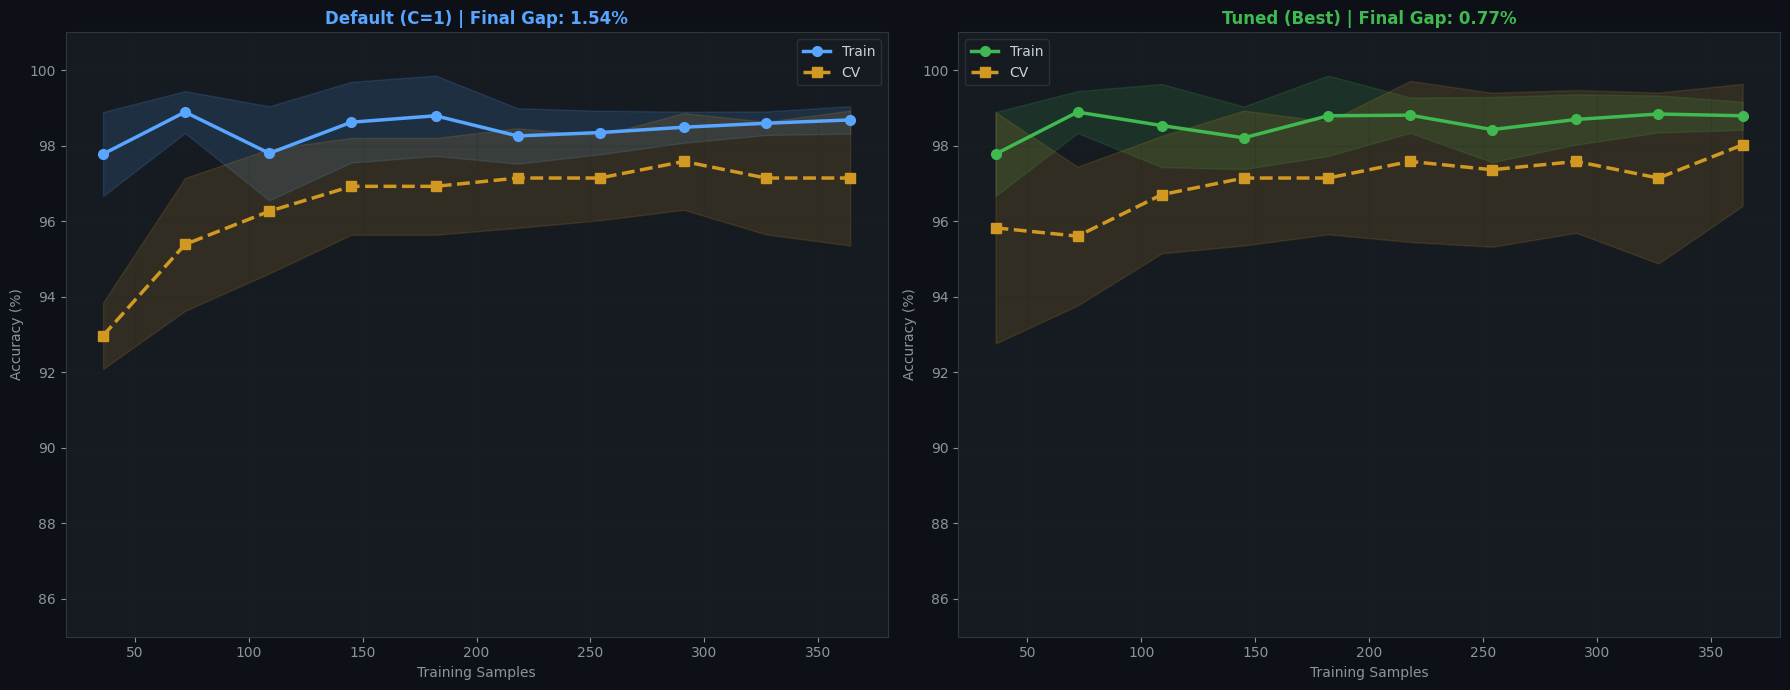

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), facecolor=COLORS['bg'])
models_lc = [
    ('Default (C=1)', SVC(kernel='rbf', C=1, gamma='scale', random_state=42), COLORS['primary']),
    ('Tuned (Best)',  best_model, COLORS['success']),
]
for ax, (label, model, color) in zip(axes, models_lc):
    train_sz, tr_sc, val_sc = learning_curve(
        model, X_train_sc, y_train,
        train_sizes=np.linspace(0.1,1.0,10), cv=5, scoring='accuracy', n_jobs=-1)
    tr_m, tr_s = tr_sc.mean(axis=1)*100, tr_sc.std(axis=1)*100
    vl_m, vl_s = val_sc.mean(axis=1)*100, val_sc.std(axis=1)*100
    ax.plot(train_sz, tr_m, 'o-', color=color, linewidth=2.5, markersize=7, label='Train')
    ax.fill_between(train_sz, tr_m-tr_s, tr_m+tr_s, alpha=0.15, color=color)
    ax.plot(train_sz, vl_m, 's--', color=COLORS['warning'], linewidth=2.5, markersize=7, label='CV')
    ax.fill_between(train_sz, vl_m-vl_s, vl_m+vl_s, alpha=0.15, color=COLORS['warning'])
    gap = tr_m[-1] - vl_m[-1]
    ax.set_title(f'{label} | Final Gap: {gap:.2f}%', color=color, fontweight='bold')
    ax.set_xlabel('Training Samples', color='#8b949e')
    ax.set_ylabel('Accuracy (%)', color='#8b949e')
    ax.set_ylim(85, 101); ax.set_facecolor(COLORS['card']); ax.grid(alpha=0.2)
    ax.legend(facecolor=COLORS['card'], edgecolor=COLORS['border'], labelcolor='#c9d1d9')
plt.tight_layout()
plt.savefig('viz7_learning_curves.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

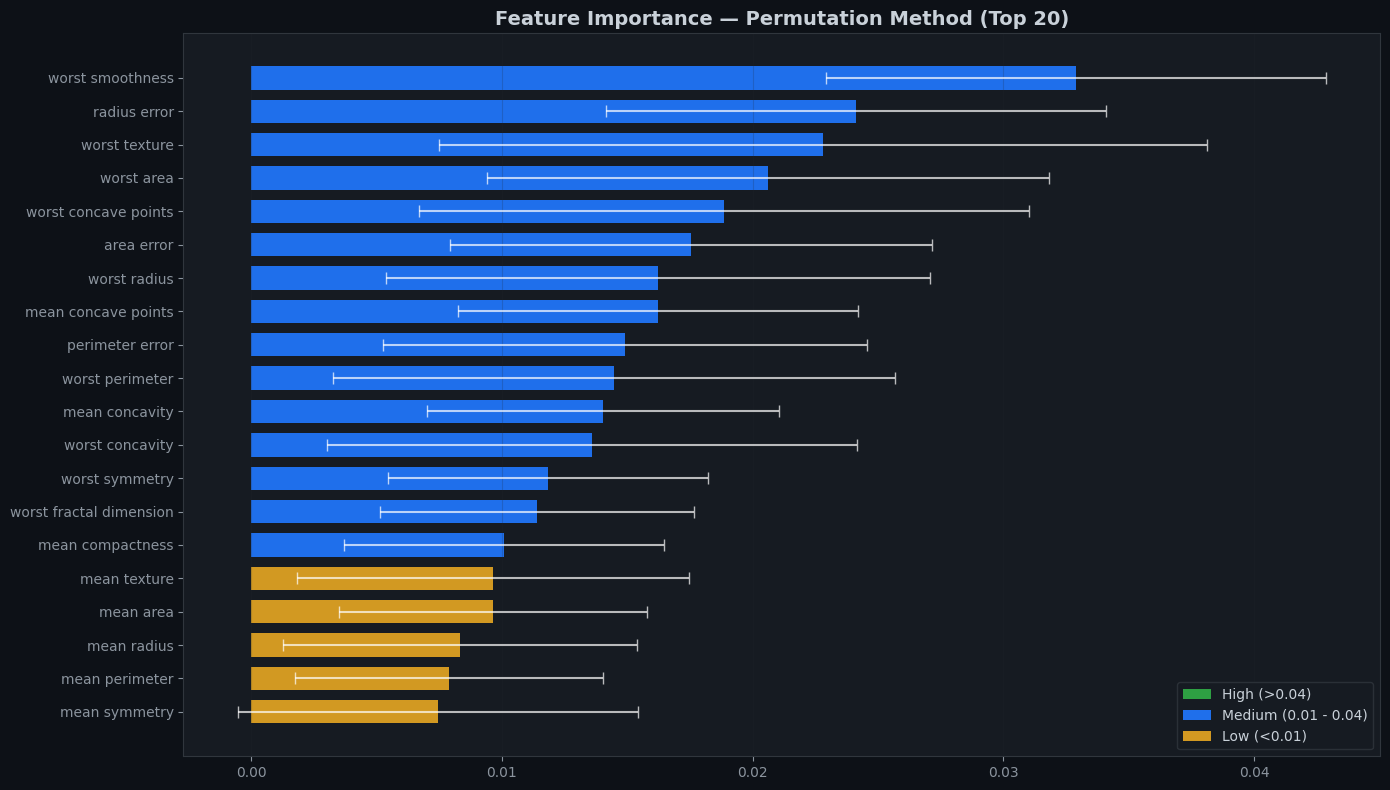

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from matplotlib.patches import Patch

# ---- Color theme (make sure these exist) ----
COLORS = {
    'bg': '#0d1117',
    'card': '#161b22',
    'border': '#30363d',
    'success': '#2ea043',
    'primary': '#1f6feb',
    'warning': '#d29922'
}

# ---- Permutation Importance ----
perm_imp = permutation_importance(
    best_model,
    X_test_sc,
    y_test,
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# ---- Sort Top 20 Features ----
sorted_idx = perm_imp.importances_mean.argsort()[::-1][:20]

feat_names = np.array(data.feature_names)[sorted_idx]
feat_means = perm_imp.importances_mean[sorted_idx]
feat_stds  = perm_imp.importances_std[sorted_idx]

# ---- Color Mapping ----
bar_colors = [
    COLORS['success'] if v > 0.04 else
    (COLORS['primary'] if v > 0.01 else COLORS['warning'])
    for v in feat_means
]

# ---- Plot ----
fig, ax = plt.subplots(figsize=(14, 8), facecolor=COLORS['bg'])

ax.barh(range(len(feat_names)), feat_means, color=bar_colors, height=0.7)

# Error bars
ax.errorbar(
    feat_means,
    range(len(feat_names)),
    xerr=feat_stds,
    fmt='none',
    color='white',
    capsize=4,
    linewidth=1.5,
    alpha=0.7
)

# Y-axis
ax.set_yticks(range(len(feat_names)))
ax.set_yticklabels(feat_names)
ax.invert_yaxis()

# Title
ax.set_title(
    'Feature Importance — Permutation Method (Top 20)',
    color='#c9d1d9',
    fontweight='bold',
    fontsize=14
)

# Styling
ax.set_facecolor(COLORS['card'])
ax.grid(axis='x', alpha=0.2)

# ---- Legend (FIXED) ----
ax.legend(
    handles=[
        Patch(facecolor=COLORS['success'], label='High (>0.04)'),
        Patch(facecolor=COLORS['primary'], label='Medium (0.01 - 0.04)'),
        Patch(facecolor=COLORS['warning'], label='Low (<0.01)')
    ],
    facecolor=COLORS['card'],
    edgecolor=COLORS['border'],
    labelcolor='#c9d1d9'
)

# Layout & Save
plt.tight_layout()
plt.savefig(
    'viz8_feature_importance.png',
    dpi=150,
    bbox_inches='tight',
    facecolor=COLORS['bg']
)

plt.show()

In [14]:
import os
print(os.listdir())

['viz2_kernel_comparison.png', 'viz6_gridsearch_heatmap.png', 'viz3_confusion_matrices.png', 'viz1_eda_dashboard.png', 'viz7_learning_curves.png', 'viz8_feature_importance.png', 'viz4_roc_pr_curves.png', '.virtual_documents', 'Heatmap.png', 'viz5_decision_boundaries.png']


In [5]:
# -------------------------
# 3. Load Dataset
# -------------------------
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

class_names = data.target_names  # ['malignant', 'benign']

print("📌 Dataset Shape:", X.shape)
print("📌 Target Distribution:\n", y.value_counts())
print("\n✅ Dataset loaded successfully!")

📌 Dataset Shape: (569, 30)
📌 Target Distribution:
 target
1    357
0    212
Name: count, dtype: int64

✅ Dataset loaded successfully!


In [6]:
# -------------------------
# 4. Quick Data Overview
# -------------------------
display(X.head())

summary_df = pd.DataFrame({
    'Feature': X.columns,
    'Mean': X.mean().values,
    'Std Dev': X.std().values,
    'Min': X.min().values,
    'Max': X.max().values
})

display(summary_df.head(10))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,Feature,Mean,Std Dev,Min,Max
0,mean radius,14.127292,3.524049,6.98100,28.11000
1,mean texture,19.289649,4.301036,9.71000,39.28000
2,mean perimeter,91.969033,24.298981,43.79000,188.50000
3,mean area,654.889104,351.914129,143.50000,2501.00000
4,mean smoothness,0.096360,0.014064,0.05263,0.16340
5,mean compactness,0.104341,0.052813,0.01938,0.34540
6,mean concavity,0.088799,0.079720,0.00000,0.42680
7,mean concave points,0.048919,0.038803,0.00000,0.20120
8,mean symmetry,0.181162,0.027414,0.10600,0.30400
9,mean fractal dimension,0.062798,0.007060,0.04996,0.09744


In [7]:
# -------------------------
# 5. Train-Test Split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"✅ Training samples: {X_train.shape[0]}")
print(f"✅ Testing samples : {X_test.shape[0]}")

✅ Training samples: 455
✅ Testing samples : 114


In [9]:
# -------------------------
# 6. Feature Scaling
# -------------------------
# GaussianNB can work without scaling, but scaling helps cleaner visualization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_scaled = scaler.fit_transform(X)

In [11]:
# Core Libraries
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, cross_val_score, learning_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance

# Visualization
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

print("✅ All libraries loaded successfully!")

✅ All libraries loaded successfully!


In [12]:
# -------------------------
# 7. Train Gaussian Naive Bayes Model
# -------------------------
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_test_scaled)
y_proba = nb_model.predict_proba(X_test_scaled)[:, 1]

print("✅ Gaussian Naive Bayes model trained successfully!")

✅ Gaussian Naive Bayes model trained successfully!


In [13]:
# -------------------------
# 8. Performance Metrics
# -------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

cv_scores = cross_val_score(nb_model, X_scaled, y, cv=5, scoring='accuracy')

print("=" * 60)
print("📊 MODEL PERFORMANCE SUMMARY")
print("=" * 60)
print(f"Accuracy           : {accuracy:.4f}")
print(f"Precision          : {precision:.4f}")
print(f"Recall             : {recall:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"5-Fold CV Accuracy : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("=" * 60)

📊 MODEL PERFORMANCE SUMMARY
Accuracy           : 0.9298
Precision          : 0.9444
Recall             : 0.9444
F1 Score           : 0.9444
5-Fold CV Accuracy : 0.9279 ± 0.0204


In [14]:
# -------------------------
# 9. Classification Report
# -------------------------
report = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
display(report_df.style.background_gradient(cmap='Blues').format("{:.4f}"))

,precision,recall,f1-score,support
malignant,0.9048,0.9048,0.9048,42.0000
benign,0.9444,0.9444,0.9444,72.0000
accuracy,0.9298,0.9298,0.9298,0.9298
macro avg,0.9246,0.9246,0.9246,114.0000
weighted avg,0.9298,0.9298,0.9298,114.0000


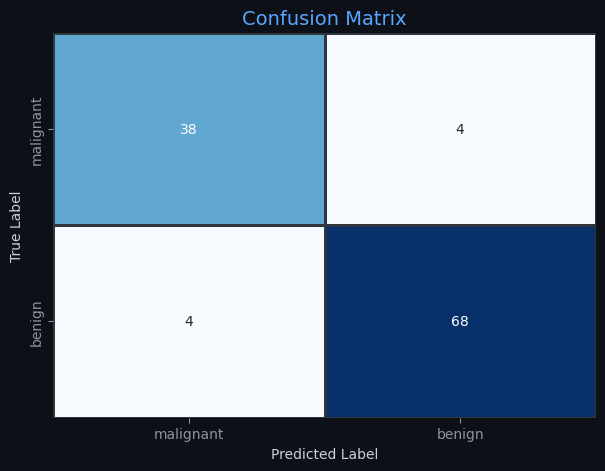

In [15]:
# -------------------------
# 10. Confusion Matrix
# -------------------------
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    cbar=False, linewidths=1, linecolor=COLORS['border']
)
plt.title("Confusion Matrix", fontsize=14, color=COLORS['primary'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

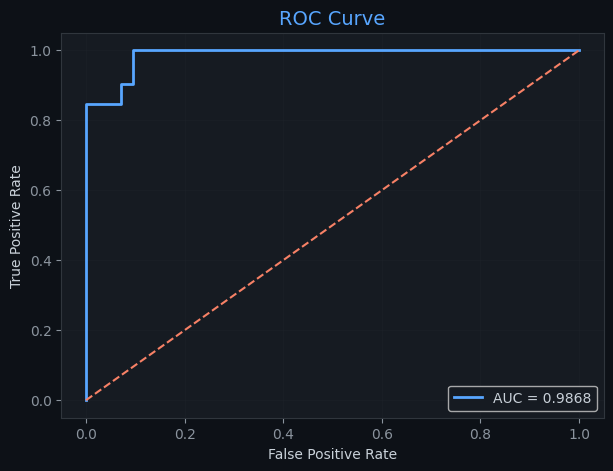

In [16]:
# -------------------------
# 11. ROC Curve
# -------------------------
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color=COLORS['primary'], lw=2, label=f'AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], linestyle='--', color=COLORS['secondary'])
plt.title("ROC Curve", fontsize=14, color=COLORS['primary'])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

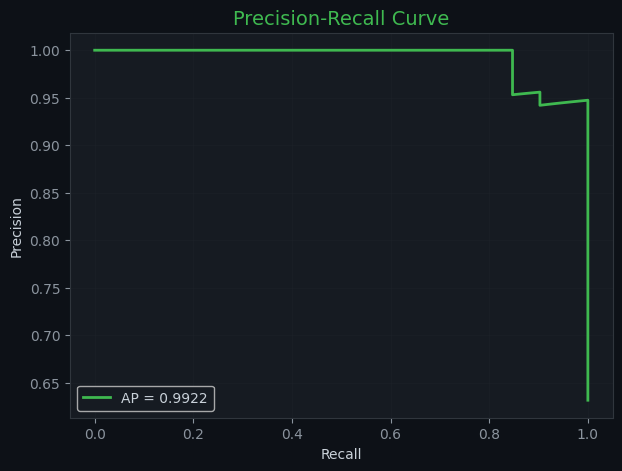

In [17]:
# -------------------------
# 12. Precision-Recall Curve
# -------------------------
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_proba)
avg_precision = average_precision_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(recall_vals, precision_vals, color=COLORS['success'], lw=2,
         label=f'AP = {avg_precision:.4f}')
plt.title("Precision-Recall Curve", fontsize=14, color=COLORS['success'])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

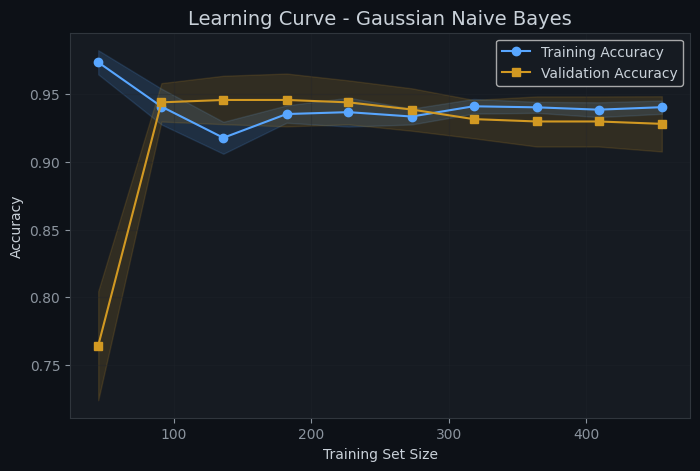

In [18]:
# -------------------------
# 13. Learning Curve
# -------------------------
train_sizes, train_scores, val_scores = learning_curve(
    nb_model, X_scaled, y,
    cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker='o', color=COLORS['primary'], label='Training Accuracy')
plt.plot(train_sizes, val_mean, marker='s', color=COLORS['warning'], label='Validation Accuracy')

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                 alpha=0.15, color=COLORS['primary'])
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                 alpha=0.15, color=COLORS['warning'])

plt.title("Learning Curve - Gaussian Naive Bayes", fontsize=14)
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

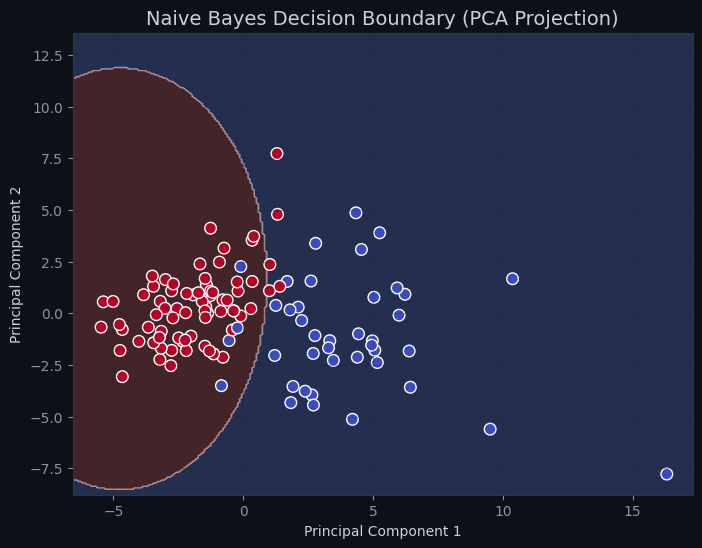

In [24]:
# -------------------------
# 14. PCA Decision Space Visualization
# -------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca, y, test_size=0.2, stratify=y, random_state=42
)

nb_pca = GaussianNB()
nb_pca.fit(X_train_pca, y_train_pca)

# Meshgrid
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

Z = nb_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')

scatter = plt.scatter(
    X_test_pca[:, 0], X_test_pca[:, 1],
    c=y_test_pca, cmap='coolwarm',
    edgecolor='white', s=70
)

plt.title("Naive Bayes Decision Boundary (PCA Projection)", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.savefig('Naive Bayes Decision_Boundary.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

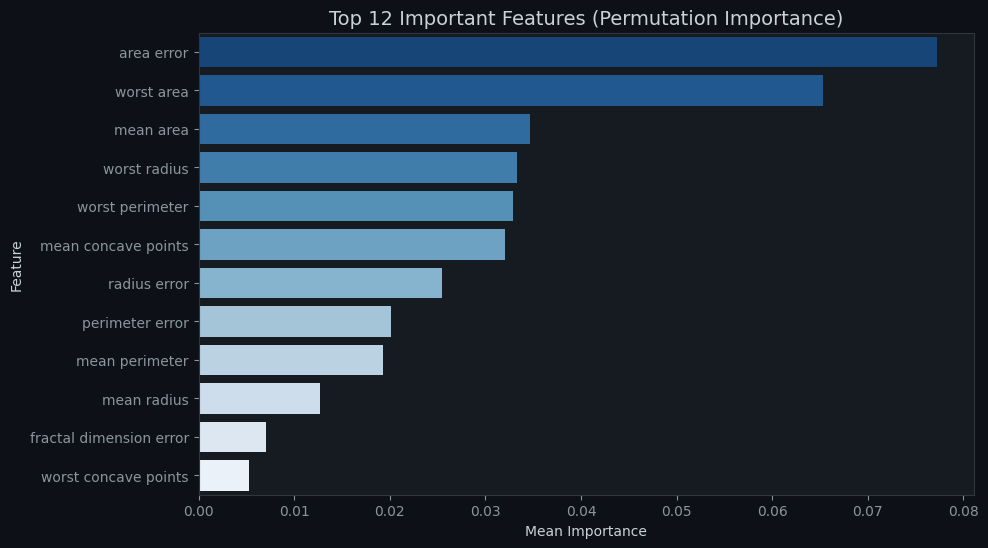

ValueError: Unknown format code 'f' for object of type 'str'

In [23]:
# -------------------------
# 15. Permutation Feature Importance
# -------------------------
perm_importance = permutation_importance(
    nb_model, X_test_scaled, y_test,
    n_repeats=20, random_state=42, scoring='accuracy'
)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
}).sort_values(by='Importance Mean', ascending=False)

top_features = importance_df.head(12)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x='Importance Mean', y='Feature',
    palette='Blues_r'
)
plt.title("Top 12 Important Features (Permutation Importance)", fontsize=14)
plt.xlabel("Mean Importance")
plt.ylabel("Feature")
plt.show()

display(importance_df.head(12).style.background_gradient(cmap='Blues').format("{:.4f}"))

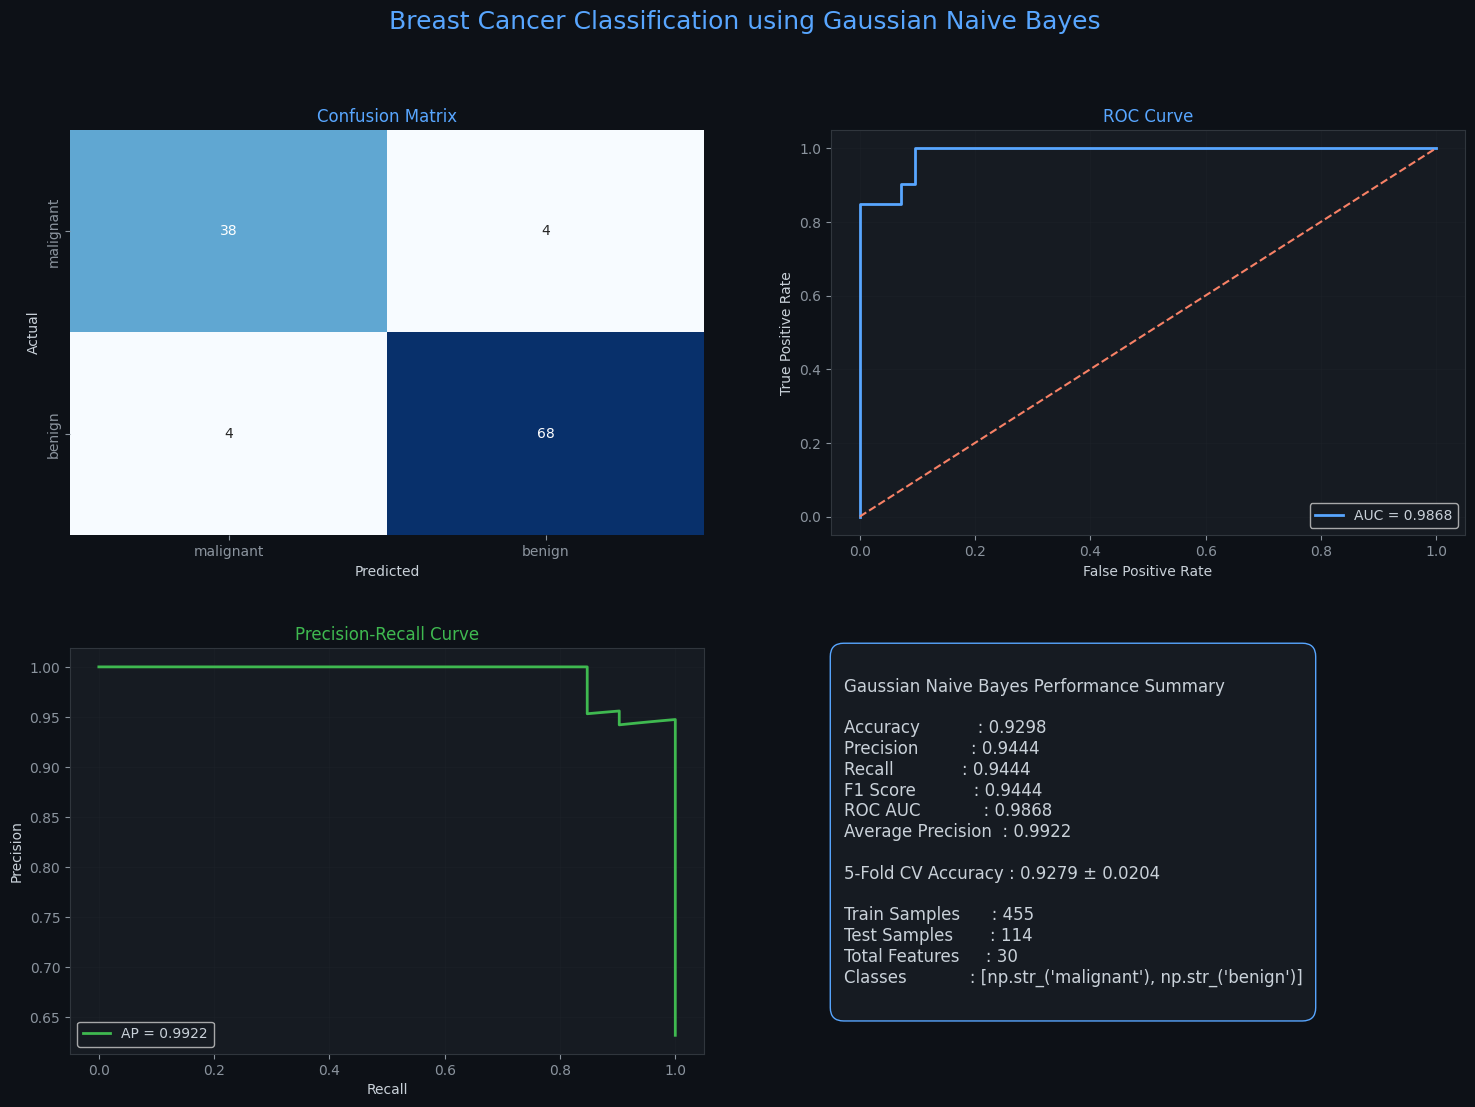

In [25]:
# -------------------------
# 16. Final Dashboard Plot
# -------------------------
fig = plt.figure(figsize=(18, 12))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.28, wspace=0.20)

# Confusion Matrix
ax1 = fig.add_subplot(gs[0, 0])
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    cbar=False, ax=ax1
)
ax1.set_title("Confusion Matrix", color=COLORS['primary'])
ax1.set_xlabel("Predicted")
ax1.set_ylabel("Actual")

# ROC Curve
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(fpr, tpr, color=COLORS['primary'], lw=2, label=f"AUC = {roc_auc:.4f}")
ax2.plot([0, 1], [0, 1], linestyle='--', color=COLORS['secondary'])
ax2.set_title("ROC Curve", color=COLORS['primary'])
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.legend()
ax2.grid(True, alpha=0.3)

# Precision-Recall Curve
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(recall_vals, precision_vals, color=COLORS['success'], lw=2,
         label=f"AP = {avg_precision:.4f}")
ax3.set_title("Precision-Recall Curve", color=COLORS['success'])
ax3.set_xlabel("Recall")
ax3.set_ylabel("Precision")
ax3.legend()
ax3.grid(True, alpha=0.3)

# Metrics Text Panel
ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')

summary_text = f"""
Gaussian Naive Bayes Performance Summary

Accuracy           : {accuracy:.4f}
Precision          : {precision:.4f}
Recall             : {recall:.4f}
F1 Score           : {f1:.4f}
ROC AUC            : {roc_auc:.4f}
Average Precision  : {avg_precision:.4f}

5-Fold CV Accuracy : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}

Train Samples      : {X_train.shape[0]}
Test Samples       : {X_test.shape[0]}
Total Features     : {X.shape[1]}
Classes            : {list(class_names)}
"""

ax4.text(
    0.02, 0.98, summary_text,
    va='top', ha='left',
    fontsize=12,
    bbox=dict(boxstyle='round,pad=0.8', facecolor=COLORS['card'], edgecolor=COLORS['primary'])
)

fig.suptitle("Breast Cancer Classification using Gaussian Naive Bayes", fontsize=18, color=COLORS['primary'])
plt.savefig('All_Result_Naive_bayes.png', dpi=150, bbox_inches='tight', facecolor=COLORS['bg'])
plt.show()

In [22]:
# -------------------------
# 17. Final Result Table
# -------------------------
results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC', 'Average Precision', 'CV Mean Accuracy', 'CV Std'],
    'Score': [accuracy, precision, recall, f1, roc_auc, avg_precision, cv_scores.mean(), cv_scores.std()]
})

display(
    results_df.style
    .background_gradient(cmap='Blues')
    .format({'Score': '{:.4f}'})
    .set_caption("Final Performance Metrics of Gaussian Naive Bayes")
)

,Metric,Score
0,Accuracy,0.9298
1,Precision,0.9444
2,Recall,0.9444
3,F1 Score,0.9444
4,ROC AUC,0.9868
5,Average Precision,0.9922
6,CV Mean Accuracy,0.9279
7,CV Std,0.0204
